# Are Chinese adult heights approximately normally distributed?

This notebook uses the **China Health and Nutrition Survey (CHNS), 2011**. It analyzes **12,519 adults aged 20+** with recorded heights, separately for men, women, and pooled adults.

**The central distributions are roughly bell-shaped, but the recorded data have substantial lower-tail departures from normality.** Thirteen heights below 120 cm have a large effect on the tails. We retain them in the primary analysis and show a separate sensitivity analysis.

CHNS describes people sampled from selected Chinese communities; it is **not a nationally representative estimate of all Chinese adults**. Each observation contributes equally because the CHNS archive does not provide national sampling factors.

## 1. Data and reproducibility

The files were downloaded from the official [CHNS Individual-Level Data archive, UNC Dataverse, version 1.0](https://doi.org/10.15139/S3/9PQ5KV). The physical-examination file ends in **2011**, so we use that single wave rather than combining repeated observations across survey years. This is the latest wave in this particular height file, not the latest CHNS survey ever conducted.

| Source file | Fields used | Documentation | Download |
|---|---|---|---|
| `pexam_00.sas7bdat` | Person ID, wave, height (cm), height-cleaning code | [Examination codebook](https://dataverse.unc.edu/api/access/datafile/7504991) | [SAS](https://dataverse.unc.edu/api/access/datafile/7504992) |
| `surveys_pub_12.sas7bdat` | Person ID, wave, age | [Survey codebook](https://dataverse.unc.edu/api/access/datafile/7504999) | [SAS](https://dataverse.unc.edu/api/access/datafile/7505000) |
| `mast_pub_12.sas7bdat` | Person ID, sex | [Master codebook](https://dataverse.unc.edu/api/access/datafile/7504949) | [SAS](https://dataverse.unc.edu/api/access/datafile/7504950) |

The [CHNS cohort profile](https://doi.org/10.1093/ije/dyp322) describes the sample design and its limits. The [official sampling note](https://dataverse.unc.edu/api/access/datafile/7505036) explains the absence of national sampling factors.

The neighboring `data/CHNS_2011_adult_heights.npz` is a compact adult-only extract. It retains height, age, sex, and height-record information; linkage identifiers are dropped. `CHNS_2011_provenance.json` records source URLs, archive checksums, the extraction procedure, and sample counts.

**Run All** reproduces the analysis offline from the extract. To rebuild it from the official source files, run `python analysis/height_normality/prepare_china_height.py` from the repository root. This downloads about 226 MB to a temporary cache. Python, NumPy, pandas, SciPy, Matplotlib, and a Jupyter Python kernel are required.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import tempfile

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "height-mpl"))

import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

%matplotlib inline
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})

candidates = [Path.cwd(), Path.cwd() / "analysis/height_normality"]
BASE = next((p for p in candidates if (p / "data/CHNS_2011_adult_heights.npz").exists()), None)
if BASE is None:
    raise FileNotFoundError("Run from the notebook directory or repository root, with the CHNS extract present.")

provenance = json.loads((BASE / "data/CHNS_2011_provenance.json").read_text())
extract_path = BASE / "data/CHNS_2011_adult_heights.npz"
assert hashlib.sha256(extract_path.read_bytes()).hexdigest() == provenance["extract"]["sha256"]
with np.load(extract_path, allow_pickle=False) as archive:
    roster = pd.DataFrame({name: archive[name] for name in archive.files})

We select `WAVE = 2011` and `AGE >= 20` in the source survey roster, join sex from the master file, then join height on person ID and wave. The preparation script validates one record per person within the selected wave. Sex is `GENDER = 1` for male and `2` for female; age uses the survey's supplied `AGE` field.

The primary analysis retains all finite, positive heights with known sex. **No height extremes are trimmed.** Missing heights are excluded. The source height-cleaning flag (`CLN_HT`) is missing throughout the selected wave, so it cannot resolve the unusually low records.

In [2]:
assert roster.age.ge(20).all()
assert roster.sex.isin([1, 2]).all()
assert roster.height_cleaning_code.isna().all()
valid = np.isfinite(roster.height_cm) & roster.height_cm.gt(0) & roster.sex.isin([1, 2])
adults = roster.loc[valid].copy()
groups = {
    "Adults 20+, pooled": adults,
    "Men 20+": adults.loc[adults.sex.eq(1)],
    "Women 20+": adults.loc[adults.sex.eq(2)],
}
adult_names = list(groups)
sample_flow = pd.Series({
    "Adult survey roster, 2011": len(roster),
    "Adult examination record available": int(roster.exam_record_available.sum()),
    "Adults with missing height": int(roster.height_cm.isna().sum()),
    "Analysis sample, adults 20+": len(adults),
    "Men with recorded height": len(groups["Men 20+"]),
    "Women with recorded height": len(groups["Women 20+"]),
}, name="Count").to_frame()
assert len(adults) == provenance["sample_flow"]["adult_valid_height"]
display(sample_flow)

,Count
"Adult survey roster, 2011",12978
Adult examination record available,12916
Adults with missing height,459
"Analysis sample, adults 20+",12519
Men with recorded height,5835
Women with recorded height,6684


## 2. How normality is assessed

We fit the same normal approximation used in the US notebook, with equal contributions from the $n$ observations in each group:

$$\widehat\mu = \frac{1}{n}\sum_i h_i, \qquad
\widehat\sigma = \sqrt{\frac{1}{n}\sum_i (h_i-\widehat\mu)^2}.$$

The second quantity describes the spread of heights. We compare histograms and normal Q–Q plots and report:

- **Coverage:** a normal distribution has 68.27% within one SD and 95.45% within two SDs.
- **Skewness and excess kurtosis:** both equal zero for a normal distribution.
- **Maximum CDF gap:** $\sup_h|\widehat F(h)-\Phi((h-\widehat\mu)/\widehat\sigma)|$. A value of 0.02 corresponds to a difference of at most two percentage points in cumulative percentages.

CDF gaps are descriptive distances, not p-values. They emphasize cumulative probability differences, while skewness and kurtosis are particularly sensitive to extreme observations. The survey's clustered sampling also means ordinary independent-sample normality tests would not provide design-adjusted inference.

In [3]:
def empirical_distribution(frame):
    """Aggregate ties before evaluating both sides of empirical CDF jumps."""
    x = frame.height_cm.to_numpy()
    shares = np.full(len(frame), 1.0 / len(frame))
    order = np.argsort(x)
    heights, first = np.unique(x[order], return_index=True)
    masses = np.add.reduceat(shares[order], first)
    cumulative = np.cumsum(masses)
    return heights, masses, cumulative


def cdf_distance(frame, cdf):
    heights, masses, cumulative = empirical_distribution(frame)
    fitted = cdf(heights)
    return float(np.max(np.maximum(
        np.abs(cumulative - fitted),
        np.abs(cumulative - masses - fitted),
    )))


def summarize(frame):
    x = frame.height_cm.to_numpy()
    shares = np.full(len(frame), 1.0 / len(frame))
    mean = float(np.sum(shares * x))
    sd = float(np.sqrt(np.sum(shares * (x - mean) ** 2)))
    z = (x - mean) / sd
    heights, _, cumulative = empirical_distribution(frame)
    probabilities = np.array([.01, .025, .05, .5, .95, .975, .99])
    observed = heights[np.searchsorted(cumulative, probabilities)]
    fitted = norm.ppf(probabilities, loc=mean, scale=sd)
    return {
        "n": len(frame),
        "mean_cm": mean,
        "sd_cm": sd,
        "skewness": float(np.sum(shares * z ** 3)),
        "excess_kurtosis": float(np.sum(shares * z ** 4) - 3),
        "within_1_sd_pct": float(100 * np.sum(shares[np.abs(z) <= 1])),
        "within_2_sd_pct": float(100 * np.sum(shares[np.abs(z) <= 2])),
        "within_3_sd_pct": float(100 * np.sum(shares[np.abs(z) <= 3])),
        "max_cdf_gap": cdf_distance(frame, lambda h: norm.cdf(h, mean, sd)),
        "quantiles": [
            {"probability": float(p), "observed_cm": float(o), "normal_cm": float(f)}
            for p, o, f in zip(probabilities, observed, fitted)
        ],
    }

In [4]:
results = {name: summarize(frame) for name, frame in groups.items()}

def summary_table(statistics):
    table = pd.DataFrame(statistics).T[
        ["n", "mean_cm", "sd_cm", "within_1_sd_pct", "within_2_sd_pct"]
    ]
    table.columns = ["n", "Mean (cm)", "SD (cm)", "Within 1 SD (%)", "Within 2 SD (%)"]
    return table.style.format({
        "n": "{:,.0f}", "Mean (cm)": "{:.2f}", "SD (cm)": "{:.2f}",
        "Within 1 SD (%)": "{:.2f}", "Within 2 SD (%)": "{:.2f}",
    })

def shape_table(statistics):
    table = pd.DataFrame(statistics).T[["skewness", "excess_kurtosis", "max_cdf_gap"]]
    table["max_cdf_gap"] *= 100
    table.columns = ["Skewness", "Excess kurtosis", "Max CDF gap (pp)"]
    return table.style.format("{:.3f}")

display(summary_table(results))
display(shape_table(results))

,n,Mean (cm),SD (cm),Within 1 SD (%),Within 2 SD (%)
"Adults 20+, pooled","12,519",161.33,9.12,68.70,96.29
Men 20+,"5,835",167.36,7.55,72.78,96.98
Women 20+,"6,684",156.07,6.82,70.39,95.83


,Skewness,Excess kurtosis,Max CDF gap (pp)
"Adults 20+, pooled",-0.672,6.047,2.617
Men 20+,-2.119,25.461,4.462
Women 20+,-1.158,9.619,4.746


In [5]:
male, female = results["Men 20+"], results["Women 20+"]
display(Markdown(
    "The fitted normal reference curves, with height in centimeters, are\n\n"
    rf"$$N_{{\mathrm{{men}}}} = \mathcal{{N}}({male['mean_cm']:.2f},\;{male['sd_cm']:.2f}^2),"
    rf"\qquad N_{{\mathrm{{women}}}} = \mathcal{{N}}({female['mean_cm']:.2f},\;{female['sd_cm']:.2f}^2).$$"
    "\n\nThe second argument is the **variance**. These are reference fits, not a conclusion that the data are normal. "
    f"The proportions within two SDs are {male['within_2_sd_pct']:.2f}% and {female['within_2_sd_pct']:.2f}%. "
    "Coverage near 95% can coexist with strong tail departures, particularly when extreme observations inflate the fitted SD."
))

The fitted normal reference curves, with height in centimeters, are

$$N_{\mathrm{men}} = \mathcal{N}(167.36,\;7.55^2),\qquad N_{\mathrm{women}} = \mathcal{N}(156.07,\;6.82^2).$$

The second argument is the **variance**. These are reference fits, not a conclusion that the data are normal. The proportions within two SDs are 96.98% and 95.83%. Coverage near 95% can coexist with strong tail departures, particularly when extreme observations inflate the fitted SD.

## 3. Histograms and normal Q–Q plots

The layout matches the US notebook: pooled adults, men, and women. Every recorded height is included. The Q–Q plots aggregate ties and use the midpoint of each empirical CDF jump as the plotting position.

The orange curve is the normal fitted to each group's mean and SD. The green dashed curve for pooled adults is the mixture of the fitted male and female normals, using their observed sample shares.

In [6]:
COLORS = ["#657a8c", "#327ca4", "#9a607d"]
NORMAL_COLOR = "#c65e28"

def fitted_mixture(frame, statistics):
    share = float(frame.sex.eq(1).mean())
    male, female = statistics["Men 20+"], statistics["Women 20+"]
    def evaluate(x, cumulative=False):
        function = norm.cdf if cumulative else norm.pdf
        return (share * function(x, male["mean_cm"], male["sd_cm"])
                + (1 - share) * function(x, female["mean_cm"], female["sd_cm"]))
    return evaluate


def draw_pair(hist_ax, qq_ax, frame, stats, title, color, bins, mixture=None):
    x = frame.height_cm.to_numpy()
    mean, sd = stats["mean_cm"], stats["sd_cm"]
    hist_ax.hist(x, bins=bins, density=True,
                 color=color, alpha=.72, edgecolor="white", linewidth=.7,
                 label="Measured heights")
    grid = np.linspace(bins[0], bins[-1], 600)
    hist_ax.plot(grid, norm.pdf(grid, mean, sd), color=NORMAL_COLOR,
                 linewidth=2.2, label="Fitted normal")
    if mixture is not None:
        hist_ax.plot(grid, mixture(grid), color="#257a59", linewidth=2,
                     linestyle="--", label="Mixture of sex-specific normals")
    hist_ax.set_title(title, loc="left", fontsize=13, weight="bold", pad=10)
    hist_ax.text(.03, .96,
                 f"n = {stats['n']:,}\nMean {mean:.1f} cm | SD {sd:.1f} cm",
                 transform=hist_ax.transAxes, va="top", fontsize=9,
                 bbox={"facecolor": "white", "alpha": .86, "edgecolor": "none", "pad": 3})
    hist_ax.set_xlabel("Height (cm)")
    hist_ax.set_ylabel("Density")
    hist_ax.set_xlim(bins[0], bins[-1])
    hist_ax.set_ylim(0, hist_ax.get_ylim()[1] * 1.26)

    heights, masses, cumulative = empirical_distribution(frame)
    # Empirical midpoint positions; every distinct height is shown.
    probabilities = np.clip(cumulative - masses / 2, 1e-12, 1 - 1e-12)
    expected = norm.ppf(probabilities, loc=mean, scale=sd)
    qq_ax.scatter(expected, heights, s=8, color=color, alpha=.7, linewidths=0)
    low = min(expected.min(), heights.min()) - 2
    high = max(expected.max(), heights.max()) + 2
    qq_ax.plot([low, high], [low, high], color=NORMAL_COLOR, linewidth=1.6)
    qq_ax.set(xlim=(low, high), ylim=(low, high),
              xlabel="Fitted normal quantile (cm)", ylabel="Observed height (cm)")
    qq_ax.set_title("Normal Q–Q plot", fontsize=11, loc="left")
    qq_ax.text(.04, .95,
               f"Max CDF gap: {100 * stats['max_cdf_gap']:.1f} percentage points",
               transform=qq_ax.transAxes, fontsize=9, va="top")
    for ax in (hist_ax, qq_ax):
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", color="#dedede", linewidth=.5, alpha=.7)
        ax.set_axisbelow(True)
        ax.tick_params(labelsize=9)


def plot_groups(frames, statistics, title, subtitle, bins):
    normal_mixture = fitted_mixture(frames["Adults 20+, pooled"], statistics)
    fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
    fig.suptitle(title, x=.07, ha="left", fontsize=18, fontweight="bold", y=.97)
    fig.text(.07, .923, subtitle, fontsize=11, color="#505050")
    for column, name in enumerate(adult_names):
        draw_pair(axes[0, column], axes[1, column], frames[name], statistics[name],
                  name, COLORS[column], bins,
                  mixture=normal_mixture if column == 0 else None)
    ymax = max(ax.get_ylim()[1] for ax in axes[0])
    for ax in axes[0]:
        ax.set_ylim(0, ymax)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower left", bbox_to_anchor=(.065, .865),
               ncol=3, frameon=False, fontsize=10)
    fig.subplots_adjust(left=.07, right=.98, bottom=.16, top=.81, wspace=.3, hspace=.48)
    fig.text(.07, .04,
             "Source: CHNS Individual-Level Data, UNC Dataverse. Equal contributions from observed participants.\n"
             "Orange lines: fitted normals. All observations in the indicated sample are shown. These are sample distributions, not national estimates.",
             fontsize=9, color="#505050")
    plt.show()

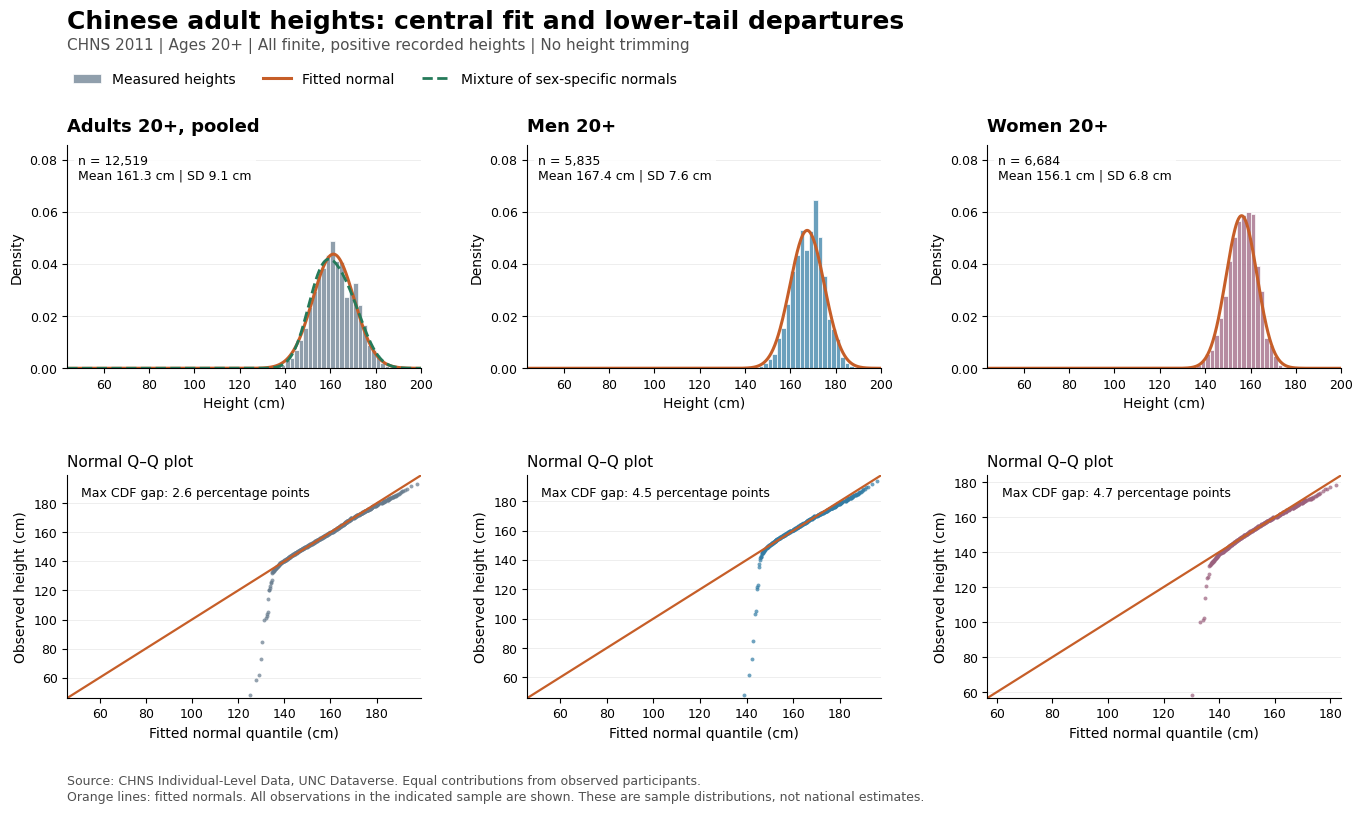

The centers are roughly bell-shaped, but the large departures in the lower Q–Q tails are clear. Large negative skewness and positive excess kurtosis show why a normal model is inadequate for the full recorded distribution.

For pooled adults, the single-normal CDF gap is 2.62 pp; the sex-specific normal mixture has gap 3.46 pp. The mixture does not improve this metric in the raw data. A small CDF gap alone can miss the importance of rare extreme values.

In [7]:
plot_groups(
    groups, results,
    "Chinese adult heights: central fit and lower-tail departures",
    "CHNS 2011 | Ages 20+ | All finite, positive recorded heights | No height trimming",
    np.arange(44, 202, 2),
)
raw_mixture = fitted_mixture(adults, results)
raw_mixture_gap = cdf_distance(adults, lambda h: raw_mixture(h, cumulative=True))
display(Markdown(
    "The centers are roughly bell-shaped, but the large departures in the lower Q–Q tails are clear. "
    "Large negative skewness and positive excess kurtosis show why a normal model is inadequate for the full recorded distribution.\n\n"
    f"For pooled adults, the single-normal CDF gap is {100 * results['Adults 20+, pooled']['max_cdf_gap']:.2f} pp; "
    f"the sex-specific normal mixture has gap {100 * raw_mixture_gap:.2f} pp. "
    "The mixture does not improve this metric in the raw data. A small CDF gap alone can miss the importance of rare extreme values."
))

## 4. Sensitivity to unusually low recorded heights

There are **13 heights below 120 cm**, with a minimum of **48 cm**. We cannot determine from these files which are measurement or recording errors and which might be valid observations.

For sensitivity only, restrict height to **120–220 cm inclusive**. This range was chosen after inspecting the data to show the influence of the extreme low records. It is not a verified correction or a rule that all shorter adults are invalid. The primary results above retain every positive recorded height.

Sensitivity sample: 12,506 adults; 13 records excluded.


,n,Mean (cm),SD (cm),Within 1 SD (%),Within 2 SD (%)
"Adults 20+, pooled","12,506",161.40,8.79,67.22,95.87
Men 20+,"5,829",167.45,6.98,68.67,95.90
Women 20+,"6,677",156.13,6.53,69.75,95.21


,Skewness,Excess kurtosis,Max CDF gap (pp)
"Adults 20+, pooled",-0.040,-0.056,3.239
Men 20+,-0.313,1.041,4.884
Women 20+,-0.358,0.515,4.355


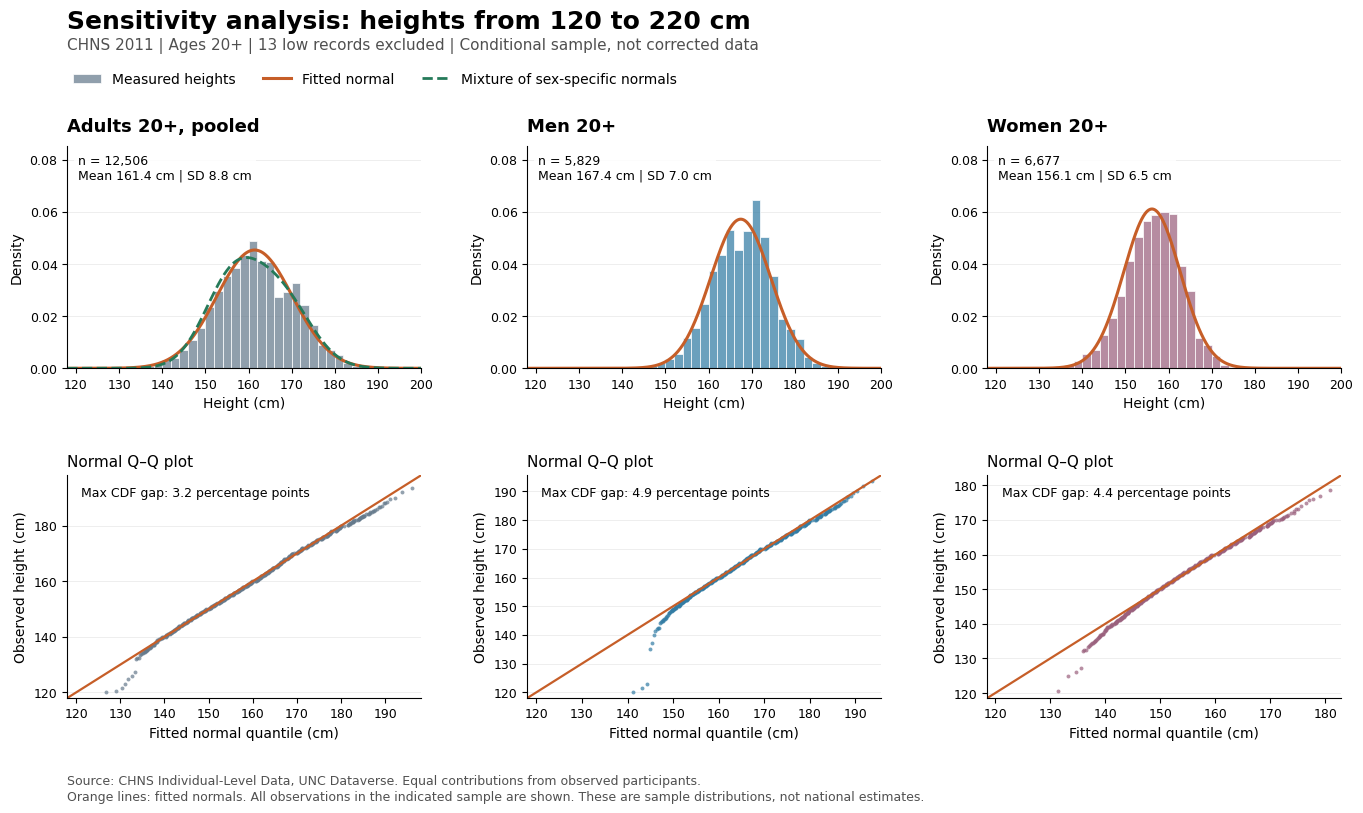

Excluding the extreme low entries markedly reduces skewness and excess kurtosis. The sex-specific normal curves are useful approximations to the central distributions, but lower-tail departures and discreteness remain. This does not establish exact normality, and the selected range is an analytical sensitivity choice.

For the pooled sensitivity sample, the CDF gap changes from 3.24 pp for one normal to 2.67 pp for the sex-specific mixture. The mixture has more parameters; this is an in-sample descriptive comparison.

In [8]:
in_range = adults.height_cm.between(120, 220)
screened = adults.loc[in_range].copy()
screened_groups = {
    "Adults 20+, pooled": screened,
    "Men 20+": screened.loc[screened.sex.eq(1)],
    "Women 20+": screened.loc[screened.sex.eq(2)],
}
screened_results = {name: summarize(frame) for name, frame in screened_groups.items()}
print(f"Sensitivity sample: {len(screened):,} adults; {len(adults) - len(screened)} records excluded.")
display(summary_table(screened_results))
display(shape_table(screened_results))
plot_groups(
    screened_groups, screened_results,
    "Sensitivity analysis: heights from 120 to 220 cm",
    "CHNS 2011 | Ages 20+ | 13 low records excluded | Conditional sample, not corrected data",
    np.arange(118, 202, 2),
)

screened_mixture = fitted_mixture(screened, screened_results)
screened_mixture_gap = cdf_distance(screened, lambda h: screened_mixture(h, cumulative=True))
display(Markdown(
    "Excluding the extreme low entries markedly reduces skewness and excess kurtosis. "
    "The sex-specific normal curves are useful approximations to the central distributions, "
    "but lower-tail departures and discreteness remain. "
    "This does not establish exact normality, and the selected range is an analytical sensitivity choice.\n\n"
    f"For the pooled sensitivity sample, the CDF gap changes from "
    f"{100 * screened_results['Adults 20+, pooled']['max_cdf_gap']:.2f} pp for one normal to "
    f"{100 * screened_mixture_gap:.2f} pp for the sex-specific mixture. "
    "The mixture has more parameters; this is an in-sample descriptive comparison."
))

## 5. Parallel with the US analysis

| Feature | `US_height.ipynb` | This notebook |
|---|---|---|
| Source | NHANES 2017–2018 | CHNS 2011 |
| Age definition | 20+ | 20+ |
| Recorded-height sample | 5,185 adults | 12,519 adults |
| Groups and diagnostics | Pooled, men, women; fitted normals and Q–Q plots | Same |
| Observation contributions | NHANES examination sampling factors | Equal contributions; national factors unavailable |
| Main finding | Separate male/female distributions close to normal | Roughly bell-shaped centers, substantial raw lower-tail deviations |
| Interpretation | Survey-adjusted US adult distribution | Distribution within the sampled Chinese communities |

The surveys differ in year, geographic coverage, age composition, and sample design. The comparison is about the diagnostic method and observed shapes; differences in means are not an estimate of a nationality effect.

**Conclusion.** A normal approximation is useful for the central portions of Chinese adult height distributions in this sample, particularly after the explicitly labeled sensitivity screen. It is a poor description of the extreme tails in the raw records. Approximate 95% coverage alone is not enough to establish a good normal fit.

No design-adjusted confidence intervals or formal normality-test p-values are calculated. Missing height and possible recording errors limit interpretation.

## 6. Sources and reproducibility record

Data attribution: **China Health and Nutrition Survey**, China CDC and the **UNC Carolina Population Center**; [Individual-Level Data, UNC Dataverse](https://doi.org/10.15139/S3/9PQ5KV), version 1.0, published 10 May 2019. Survey design reference: [Popkin et al., *International Journal of Epidemiology*, 2010](https://doi.org/10.1093/ije/dyp322).

The source archive permits public analytical use and prohibits attempts to identify or contact participants, communities, or service providers. No identifying or location fields are included in the extract or displayed in this notebook. See the archive for the complete conditions. Source data retain those terms; the analysis code and figures follow this repository's CC BY-NC-SA 4.0 license.

The source downloads were verified against the archive's published MD5 checksums. The extract's SHA256 is checked on loading. The following cell records provenance and writes the numerical results for reuse.

In [9]:
output = {
    "dataset_doi": provenance["dataset_doi"],
    "survey_year": provenance["survey_year"],
    "sample_flow": provenance["sample_flow"],
    "primary_all_recorded_heights": results,
    "sensitivity_height_120_to_220_cm": screened_results,
    "pooled_mixture_cdf_gap": {"primary": raw_mixture_gap, "sensitivity": screened_mixture_gap},
}
(BASE / "China_height_results.json").write_text(json.dumps(output, indent=2, allow_nan=False) + "\n")
print("Dataset:", provenance["dataset_doi"])
print("Adult extract SHA256:", provenance["extract"]["sha256"])
print("Source files verified against archive checksums:")
for source in provenance["sources"]:
    print(f"  {source['filename']}: MD5 {source['md5']}")

Dataset: https://doi.org/10.15139/S3/9PQ5KV
Adult extract SHA256: 3b4919cb453f1345af56bf0e4e397461595017f6d2ac2fc604a714e2677f2deb
Source files verified against archive checksums:
  mast_pub_12.sas7bdat: MD5 26eeabd1330107aa54f89d1e73f74dee
  surveys_pub_12.sas7bdat: MD5 c52cb94ef07176e52812a4ea74dcaaaf
  pexam_00.sas7bdat: MD5 a531a3b0d380fbae1baeabda3e8453f1
